# Predicting Customer Churn for a Telecom Provider

**Data Science Portfolio Assignment — Group Project (Option A)**
**TETR College of Business | Instructor: Mr Ayush Jain**

| | |
|---|---|
| **Group members** | Ismail Shaltuni (bmt_28127) · Ilia Macuka ([ID]) · Thashen Naidoo ([ID]) · Izmina Pujoor ([ID]) |
| **Dataset** | IBM Telco Customer Churn (Kaggle: `blastchar/telco-customer-churn`) |
| **Notebook created** | 16 October 2026 (v1.1 — team names added) |
| **Date of submission** | 16 October 2026 |

---

## How this notebook is organised

1. Setup and data loading
2. Data cleaning and quality checks
3. Exploratory data analysis (EDA)
4. Feature engineering (with justification)
5. Modelling — three classifiers trained and compared
6. Threshold tuning and probability calibration
7. What drives churn? Feature importance, and correlation vs causation
8. Business analysis — who should the company actually contact?
9. Fairness audit
10. Deployment readiness and limitations
11. Export of the best model + test on a new customer
12. Conclusion

> **Reproducibility:** every random process uses `RANDOM_STATE = 42`. Run all cells top to bottom (`Runtime → Run all` in Colab). The notebook takes roughly 1–2 minutes to run.

## 1. Setup and data loading

We use the standard Python data-science stack: `pandas` for tables, `matplotlib`/`seaborn` for charts and `scikit-learn` for modelling. The data loader first looks for the CSV in the repository's `data/` folder; if it is not there (for example when running on Google Colab) it downloads the identical file from IBM's public GitHub mirror of the same dataset.

In [1]:
# --- Core libraries --------------------------------------------------------
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- scikit-learn: preprocessing, models, evaluation ------------------------
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve,
                             brier_score_loss, classification_report)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Consistent, colour-blind-friendly styling for every chart in the notebook
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"No": "#4C78A8", "Yes": "#E45756"}      # blue = stayed, red = churned
FIG_DIR = "../figures" if os.path.isdir("../figures") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)
MODEL_DIR = "../models" if os.path.isdir("../models") else "models"
os.makedirs(MODEL_DIR, exist_ok=True)

def save_fig(name):
    # Save every figure so the report can reuse it; also keep it visible inline.
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()

print("pandas", pd.__version__, "| scikit-learn", __import__("sklearn").__version__)

pandas 3.0.5 | scikit-learn 1.9.1


In [2]:
# --- Load the data ---------------------------------------------------------
LOCAL_PATHS = ["../data/Telco-Customer-Churn.csv", "data/Telco-Customer-Churn.csv",
               "Telco-Customer-Churn.csv", "WA_Fn-UseC_-Telco-Customer-Churn.csv"]
MIRROR_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
              "master/data/Telco-Customer-Churn.csv")   # same file IBM published; identical to the Kaggle copy

path = next((p for p in LOCAL_PATHS if os.path.exists(p)), None)
if path is None:
    print("Local copy not found - downloading from IBM's public mirror ...")
    path = MIRROR_URL
raw = pd.read_csv(path)
print("Loaded from:", path)
print("Shape (rows, columns):", raw.shape)
raw.head()

Loaded from: ../data/Telco-Customer-Churn.csv
Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Each row is one customer. The 21 columns fall into four groups:

| Group | Columns |
|---|---|
| Identifier | `customerID` |
| Demographics | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Services subscribed | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Account & billing | `tenure` (months), `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| **Target** | `Churn` (Yes/No — did the customer leave in the last month?) |

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Data cleaning and quality checks

Three things need checking before any analysis: wrong data types, missing values and duplicates. `TotalCharges` is stored as text (`object`) even though it is a currency amount — a sign that some cells contain something that is not a number.

In [4]:
df = raw.copy()

# 2.1 Duplicates and identifier uniqueness
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# 2.2 Explicit missing values (NaN)
print("\nNaN per column (non-zero only):")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "  none")

# 2.3 Hidden missing values: TotalCharges contains blank strings
blank_mask = df["TotalCharges"].astype(str).str.strip() == ""
print("\nBlank TotalCharges cells:", blank_mask.sum())
df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

Duplicate rows: 0
Duplicate customer IDs: 0

NaN per column (non-zero only):
  none

Blank TotalCharges cells: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


**Finding:** all 11 blank `TotalCharges` cells belong to customers with `tenure = 0` — they joined this month and have not been billed yet. None of them churned. This is *structurally* missing data, not a recording error, so the correct fix is to set `TotalCharges = 0` rather than impute a median (which would invent a bill that was never issued) or drop the rows (which would remove exactly the brand-new customers a retention team cares about).

In [5]:
# 2.4 Fix TotalCharges: convert to numeric, blanks become 0 (no bill issued yet)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)

# 2.5 SeniorCitizen is coded 0/1 but is a category, not a quantity - make it explicit
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# 2.6 Tidy text columns (strip stray whitespace) and encode the target as 0/1
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

# 2.7 Sanity check: TotalCharges should be roughly tenure x MonthlyCharges
approx = df["tenure"] * df["MonthlyCharges"]
corr = np.corrcoef(approx, df["TotalCharges"])[0, 1]
print(f"Correlation between tenure x MonthlyCharges and TotalCharges: {corr:.4f}  (close to 1 => internally consistent)")

# 2.8 Value ranges for the numeric columns
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

Correlation between tenure x MonthlyCharges and TotalCharges: 0.9996  (close to 1 => internally consistent)


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


In [6]:
# 2.9 Category labels - check nothing is misspelled or inconsistent
cat_cols = [c for c in df.columns if df[c].dtype == "object" and c not in ("customerID", "Churn")]
for c in cat_cols:
    print(f"{c:18s}: {sorted(df[c].unique())}")

No typos or inconsistent labels. One quirk worth noting: six add-on columns use the label `No internet service` and `MultipleLines` uses `No phone service`. These are legitimate third categories (they encode *why* the add-on is absent) so we keep them rather than collapsing them into `No`.

**Outliers:** the numeric ranges are all plausible (tenure 0–72 months, monthly charges \$18–\$119, total charges up to \$8,685). There are no impossible values, so no rows are removed. The dataset after cleaning still has **7,043 customers** — no data was discarded.

## 3. Exploratory data analysis

### 3.1 How many customers churn?

Churned: 1,869 (26.5%)   Stayed: 5,174 (73.5%)


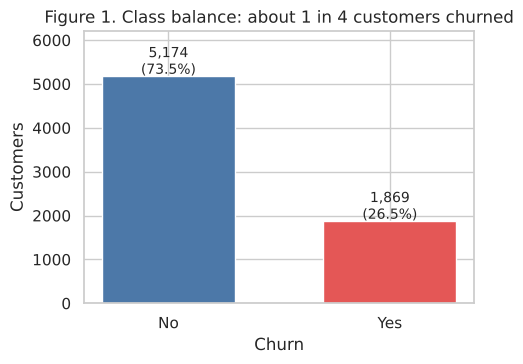

In [7]:
churn_rate = df["ChurnFlag"].mean()
counts = df["Churn"].value_counts()
print(f"Churned: {counts['Yes']:,} ({churn_rate:.1%})   Stayed: {counts['No']:,} ({1-churn_rate:.1%})")

fig, ax = plt.subplots(figsize=(5, 3.8))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[k] for k in counts.index], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 60, f"{v:,}\n({v/len(df):.1%})", ha="center", fontsize=10)
ax.set_title("Figure 1. Class balance: about 1 in 4 customers churned")
ax.set_ylabel("Customers"); ax.set_xlabel("Churn"); ax.set_ylim(0, counts.max()*1.2)
save_fig("fig01_class_balance.png")

Roughly **26.5 %** of customers churned. The classes are imbalanced (about 2.8 : 1), which matters for modelling: a model that predicts "nobody churns" would already be 73.5 % accurate while being useless. Accuracy alone is therefore a poor yardstick — precision, recall and F1 are what we optimise for.

### 3.2 Which account characteristics are linked to churn?

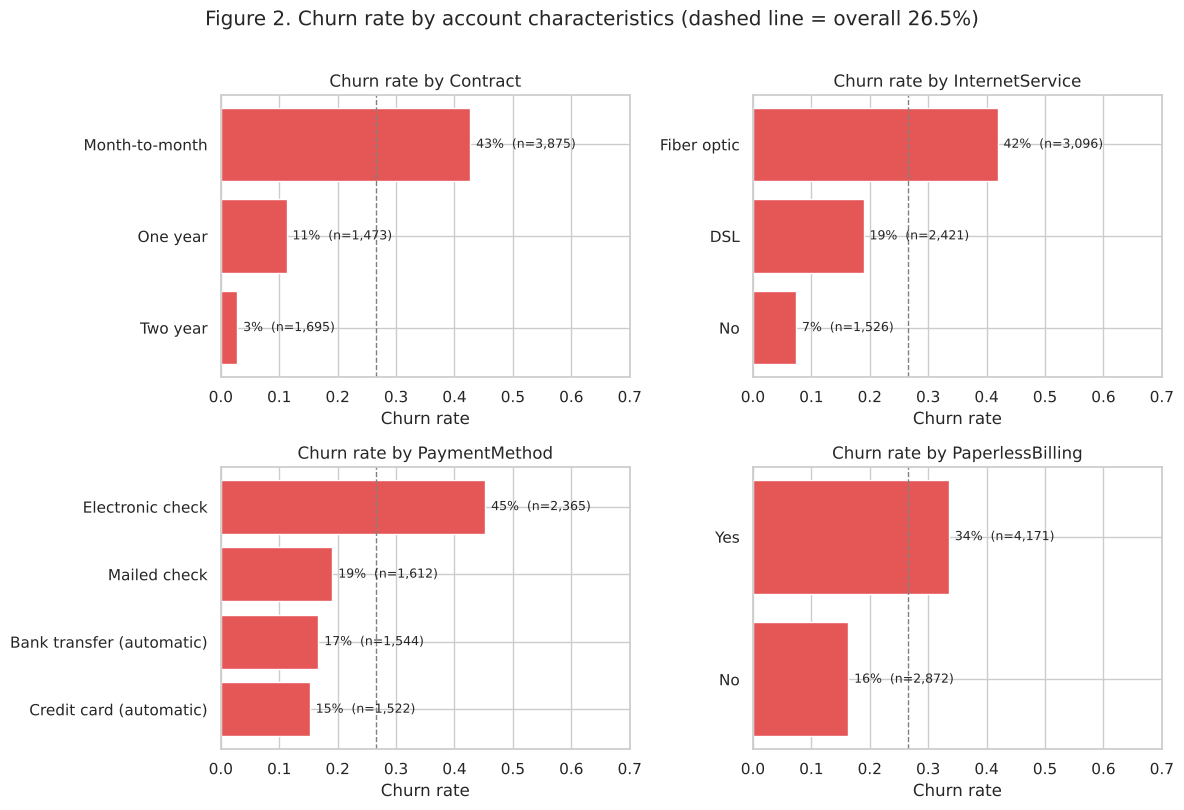

,churn_rate,customers
Contract,,
Month-to-month,42.7%,3875
One year,11.3%,1473
Two year,2.8%,1695


,churn_rate,customers
InternetService,,
Fiber optic,41.9%,3096
DSL,19.0%,2421
No,7.4%,1526


,churn_rate,customers
PaymentMethod,,
Electronic check,45.3%,2365
Mailed check,19.1%,1612
Bank transfer (automatic),16.7%,1544
Credit card (automatic),15.2%,1522


In [8]:
def churn_rate_by(col):
    g = df.groupby(col)["ChurnFlag"].agg(["mean", "size"]).rename(columns={"mean": "churn_rate", "size": "customers"})
    return g.sort_values("churn_rate", ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling"]):
    g = churn_rate_by(col)
    ax.barh(g.index, g["churn_rate"], color="#E45756")
    ax.axvline(churn_rate, ls="--", color="grey", lw=1)
    for i, (r, n) in enumerate(zip(g["churn_rate"], g["customers"])):
        ax.text(r + 0.01, i, f"{r:.0%}  (n={n:,})", va="center", fontsize=9)
    ax.set_xlim(0, 0.7); ax.set_title(f"Churn rate by {col}"); ax.set_xlabel("Churn rate")
    ax.invert_yaxis()
fig.suptitle("Figure 2. Churn rate by account characteristics (dashed line = overall 26.5%)", y=1.01)
save_fig("fig02_churn_by_account.png")

for col in ["Contract", "InternetService", "PaymentMethod"]:
    display(churn_rate_by(col).style.format({"churn_rate": "{:.1%}"}))

Three patterns stand out:

- **Contract type is the single strongest signal.** Month-to-month customers churn at ~43 %, one-year at ~11 % and two-year at under 3 %.
- **Fibre-optic internet customers churn twice as often as DSL customers** (42 % vs 19 %). Customers with no internet service hardly churn at all (7 %).
- **Electronic-check payers churn at 45 %**, far above every other payment method (15–19 %). Automatic payments (bank transfer, credit card) are associated with the lowest churn.

### 3.3 Tenure and charges

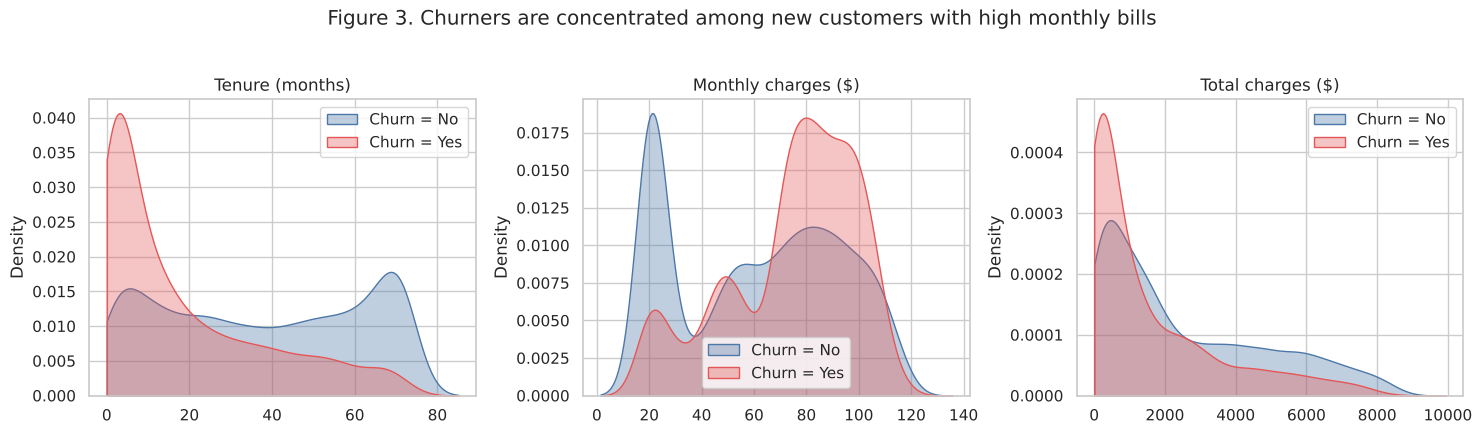

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, title in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"],
                          ["Tenure (months)", "Monthly charges ($)", "Total charges ($)"]):
    for lab in ["No", "Yes"]:
        sns.kdeplot(df.loc[df["Churn"] == lab, col], ax=ax, fill=True, alpha=0.35,
                    color=PALETTE[lab], label=f"Churn = {lab}", clip=(0, None))
    ax.set_title(title); ax.set_xlabel(""); ax.legend()
fig.suptitle("Figure 3. Churners are concentrated among new customers with high monthly bills", y=1.03)
save_fig("fig03_tenure_charges_distributions.png")

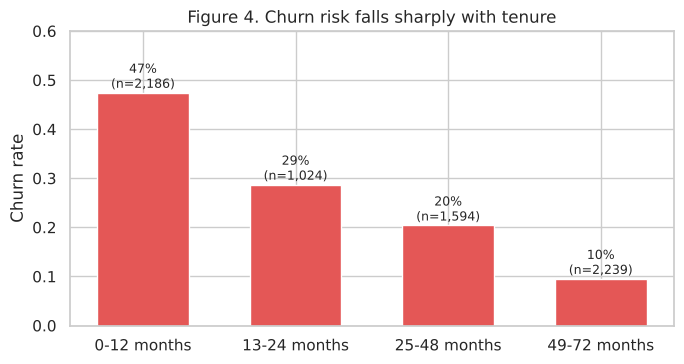

,churn_rate,customers
TenureBand,,
0-12 months,47.4%,2186
13-24 months,28.7%,1024
25-48 months,20.4%,1594
49-72 months,9.5%,2239


In [10]:
# Churn rate by tenure band
df["TenureBand"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                          labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])
band = df.groupby("TenureBand", observed=True)["ChurnFlag"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(band.index.astype(str), band["mean"], color="#E45756", width=0.6)
for i, (r, n) in enumerate(zip(band["mean"], band["size"])):
    ax.text(i, r + 0.01, f"{r:.0%}\n(n={n:,})", ha="center", fontsize=9)
ax.set_ylim(0, 0.6); ax.set_ylabel("Churn rate")
ax.set_title("Figure 4. Churn risk falls sharply with tenure")
save_fig("fig04_churn_by_tenure_band.png")
band.rename(columns={"mean": "churn_rate", "size": "customers"}).style.format({"churn_rate": "{:.1%}"})

Almost half of first-year customers leave (47 %), versus under 10 % of customers past four years. The monthly-charges chart shows churners cluster at \$70–\$100 a month — the price band of fibre-optic plans — while the \$20–\$30 band (phone-only customers) is very loyal.

### 3.4 Demographics and add-on services

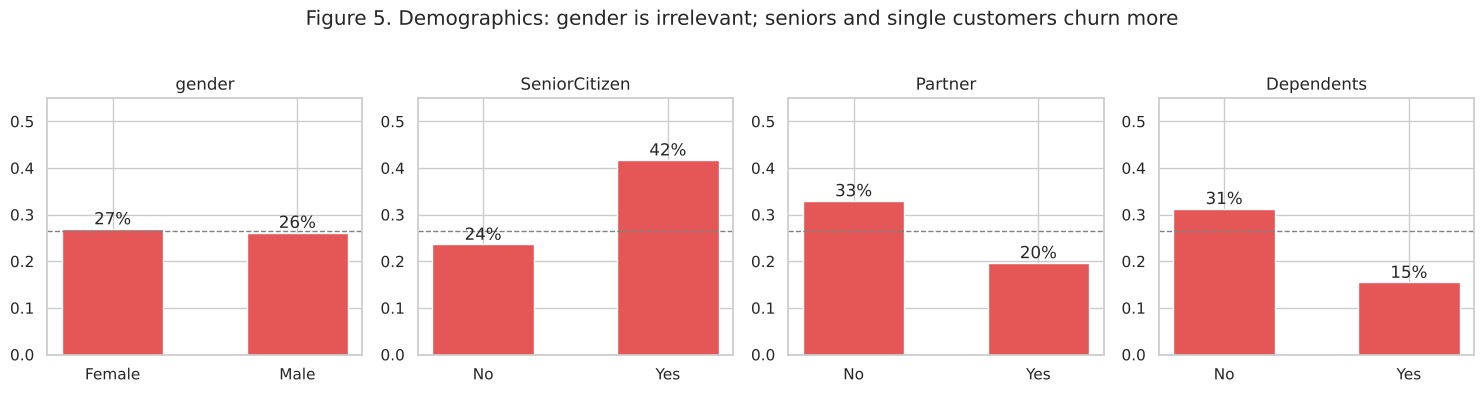

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, col in zip(axes, ["gender", "SeniorCitizen", "Partner", "Dependents"]):
    g = df.groupby(col)["ChurnFlag"].mean()
    ax.bar(g.index, g.values, color="#E45756", width=0.55)
    for i, v in enumerate(g.values):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
    ax.axhline(churn_rate, ls="--", color="grey", lw=1); ax.set_ylim(0, 0.55); ax.set_title(col)
fig.suptitle("Figure 5. Demographics: gender is irrelevant; seniors and single customers churn more", y=1.03)
save_fig("fig05_churn_by_demographics.png")

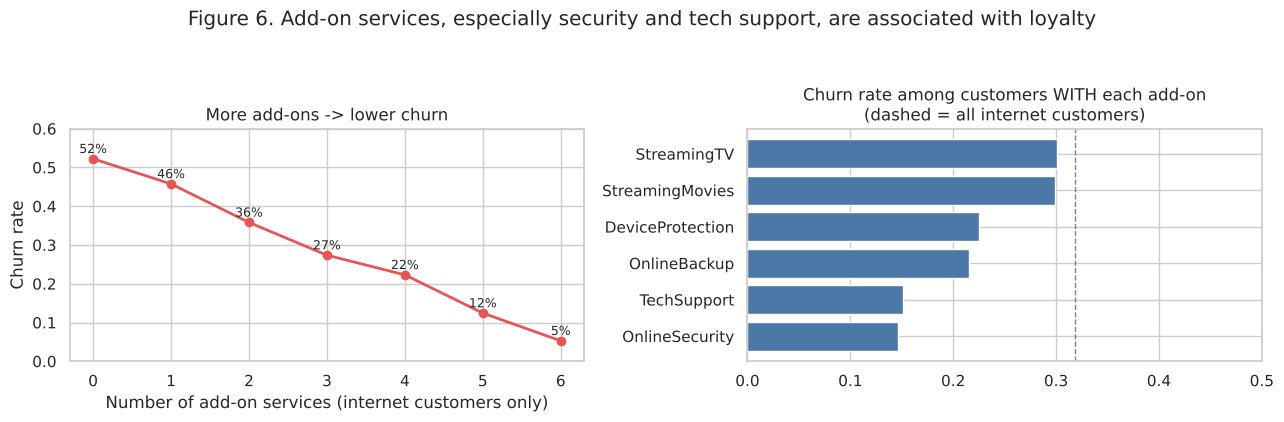

In [12]:
ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["NumAddOnServices"] = (df[ADDONS] == "Yes").sum(axis=1)

# Only internet customers can buy add-ons, so compare within that group
internet = df[df["InternetService"] != "No"]
g = internet.groupby("NumAddOnServices")["ChurnFlag"].agg(["mean", "size"])
addon_rates = (internet[ADDONS] == "Yes").apply(lambda s: internet.loc[s, "ChurnFlag"].mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(g.index, g["mean"], marker="o", color="#E45756", lw=2)
for x, (r, n) in zip(g.index, zip(g["mean"], g["size"])):
    axes[0].text(x, r + 0.015, f"{r:.0%}", ha="center", fontsize=9)
axes[0].set_xlabel("Number of add-on services (internet customers only)"); axes[0].set_ylabel("Churn rate")
axes[0].set_ylim(0, 0.6); axes[0].set_title("More add-ons -> lower churn")
axes[1].barh(addon_rates.sort_values().index, addon_rates.sort_values().values, color="#4C78A8")
axes[1].axvline(internet["ChurnFlag"].mean(), ls="--", color="grey", lw=1)
axes[1].set_xlim(0, 0.5); axes[1].set_title("Churn rate among customers WITH each add-on\n(dashed = all internet customers)")
fig.suptitle("Figure 6. Add-on services, especially security and tech support, are associated with loyalty", y=1.05)
save_fig("fig06_addon_services.png")

Customers with security-type add-ons (`OnlineSecurity`, `TechSupport`) churn at ~15 %, less than half the rate of other internet customers; streaming add-ons barely move the needle. Possible explanations: these services increase switching costs, or they are bought by customers who already intended to stay. We revisit this in Section 7.

### 3.5 Correlations between numeric variables

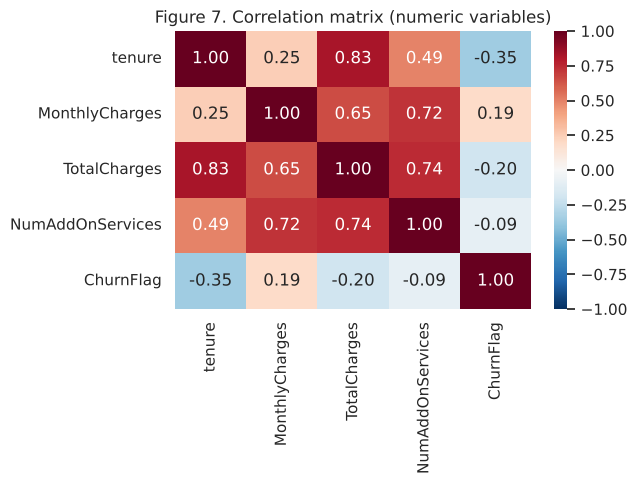

In [13]:
num_for_corr = df[["tenure", "MonthlyCharges", "TotalCharges", "NumAddOnServices", "ChurnFlag"]]
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(num_for_corr.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Figure 7. Correlation matrix (numeric variables)")
save_fig("fig07_correlation_heatmap.png")

`TotalCharges` is almost entirely explained by `tenure` × `MonthlyCharges` (r = 0.83 with tenure, 0.65 with monthly charges). Keeping all three risks multicollinearity in the logistic regression, which is one reason we engineer a cleaner spend feature in the next section. Churn correlates negatively with tenure (−0.35) and positively with monthly charges (+0.19).

## 4. Feature engineering

Each engineered feature below is motivated by a pattern in the EDA, not added speculatively.

| Feature | Definition | Why it should help |
|---|---|---|
| `NumAddOnServices` | Count of the six add-ons set to "Yes" (0–6) | Figure 6: churn falls steadily as add-ons increase; a count captures "depth of relationship" in one number. |
| `HasSecurityOrSupport` | 1 if `OnlineSecurity` **or** `TechSupport` = Yes | These two add-ons had by far the lowest churn; flags the "protected" relationship directly. |
| `AvgMonthlySpend` | `TotalCharges / tenure` (= `MonthlyCharges` when tenure = 0) | A cleaner spend measure than `TotalCharges`, which is mostly a proxy for tenure (Figure 7). |
| `ChargeRatio` | `MonthlyCharges / AvgMonthlySpend` | > 1 means the current bill is higher than the customer's historical average — a possible recent price increase or plan change, a classic churn trigger. |
| `IsNewCustomer` | 1 if `tenure` ≤ 12 | Figure 4: the first year is a distinct risk regime (47 % churn). |
| `AutoPay` | 1 if payment method is bank transfer or credit card (automatic) | Figure 2: automatic payers churn far less; collapsing four methods into a binary reduces noise. |
| `TenureBand` | Categorical 0–12 / 13–24 / 25–48 / 49–72 | Used for EDA and the causation check (Section 7); not fed to the models because `tenure` and `IsNewCustomer` already carry the information. |

Features **not** used: `customerID` (identifier with no predictive meaning) and `TotalCharges` (replaced by `AvgMonthlySpend` to reduce redundancy — tenure is kept).

We deliberately **keep** `gender`, `SeniorCitizen`, `Partner` and `Dependents` in the model so that the fairness audit in Section 9 can measure whether the model treats these groups differently. Removing a sensitive column does not remove bias if other features act as proxies; measuring is better than hiding.

In [14]:
df["HasSecurityOrSupport"] = ((df["OnlineSecurity"] == "Yes") | (df["TechSupport"] == "Yes")).astype(int)
df["AvgMonthlySpend"] = np.where(df["tenure"] > 0, df["TotalCharges"] / df["tenure"].clip(lower=1), df["MonthlyCharges"])
df["ChargeRatio"] = df["MonthlyCharges"] / df["AvgMonthlySpend"]
df["IsNewCustomer"] = (df["tenure"] <= 12).astype(int)
df["AutoPay"] = df["PaymentMethod"].str.contains("automatic").astype(int)

NUMERIC = ["tenure", "MonthlyCharges", "AvgMonthlySpend", "ChargeRatio", "NumAddOnServices"]
CATEGORICAL = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
               "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
               "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
BINARY_ENG = ["HasSecurityOrSupport", "IsNewCustomer", "AutoPay"]
FEATURES = NUMERIC + CATEGORICAL + BINARY_ENG

X = df[FEATURES].copy()
y = df["ChurnFlag"].copy()
print(f"{len(FEATURES)} input features, {len(X):,} customers")
X[["tenure", "MonthlyCharges", "AvgMonthlySpend", "ChargeRatio", "NumAddOnServices"] + BINARY_ENG].describe().round(2)

24 input features, 7,043 customers


,tenure,MonthlyCharges,AvgMonthlySpend,ChargeRatio,NumAddOnServices,HasSecurityOrSupport,IsNewCustomer,AutoPay
count,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,64.76,1.00,2.04,0.42,0.31,0.44
std,24.56,30.09,30.19,0.05,1.85,0.49,0.46,0.50
min,0.00,18.25,13.78,0.64,0.00,0.00,0.00,0.00
25%,9.00,35.50,35.94,0.98,0.00,0.00,0.00,0.00
50%,29.00,70.35,70.34,1.00,2.00,0.00,0.00,0.00
75%,55.00,89.85,90.17,1.02,3.00,1.00,1.00,1.00
max,72.00,118.75,121.40,1.45,6.00,1.00,1.00,1.00


## 5. Modelling

### 5.1 Train/test split and preprocessing pipeline

- **80 / 20 stratified split** — the test set (1,409 customers) keeps the same 26.5 % churn rate and is never touched until final evaluation.
- **Preprocessing lives inside a scikit-learn `Pipeline`** so that scaling and one-hot encoding are learned on the training data only (no leakage) and the exported model can take raw customer records as input.
- Numeric features are standardised (needed for logistic regression, harmless for trees). Categorical features are one-hot encoded; binary ones get a single column.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} customers ({y_train.mean():.1%} churn) | Test: {len(X_test):,} customers ({y_test.mean():.1%} churn)")

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CATEGORICAL),
    ("bin", "passthrough", BINARY_ENG),
])

Train: 5,634 customers (26.5% churn) | Test: 1,409 customers (26.5% churn)


### 5.2 Three classifiers, chosen to be different

| Model | Why it is here | Class-imbalance handling |
|---|---|---|
| **Logistic Regression** | Interpretable baseline; coefficients tell the retention team *why* a customer is flagged. | `class_weight="balanced"` |
| **Random Forest** | Captures non-linear interactions (e.g. fibre × month-to-month) with little tuning; robust to outliers. | `class_weight="balanced"`, depth-limited to avoid overfitting |
| **Gradient Boosting** | Usually the strongest tabular learner; produces well-calibrated probabilities, which Section 8 relies on. | No reweighting — probabilities kept honest; imbalance handled by threshold tuning instead |

All models use the same pipeline and the same 5-fold stratified cross-validation on the **training set** for a fair comparison. Hyper-parameters are modest, hand-set values (the dataset is small; aggressive tuning would mostly overfit the CV folds).

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=5,
                                            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                    subsample=0.8, random_state=RANDOM_STATE),
}
pipelines = {name: Pipeline([("prep", preprocessor), ("clf", clf)]) for name, clf in models.items()}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []
for name, pipe in pipelines.items():
    scores = {m: cross_val_score(pipe, X_train, y_train, cv=cv, scoring=m)
              for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}
    cv_results.append({"Model": name, **{m.upper(): f"{s.mean():.3f} +/- {s.std():.3f}" for m, s in scores.items()}})
cv_table = pd.DataFrame(cv_results).set_index("Model")
print("5-fold cross-validation on the training set (mean +/- std):")
cv_table

5-fold cross-validation on the training set (mean +/- std):


,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.750 +/- 0.013,0.519 +/- 0.017,0.794 +/- 0.039,0.627 +/- 0.023,0.845 +/- 0.012
Random Forest,0.756 +/- 0.012,0.528 +/- 0.016,0.791 +/- 0.026,0.633 +/- 0.015,0.846 +/- 0.009
Gradient Boosting,0.800 +/- 0.011,0.658 +/- 0.027,0.511 +/- 0.029,0.575 +/- 0.025,0.846 +/- 0.009


### 5.3 Fit on the full training set and evaluate on the held-out test set

Metrics below use the default decision threshold of 0.5 (a customer is flagged if predicted probability ≥ 0.5). Section 6 shows why 0.5 is not the right threshold for this business problem.

In [17]:
test_rows, probas = [], {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    probas[name] = p
    pred = (p >= 0.5).astype(int)
    test_rows.append({"Model": name,
                      "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                      "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                      "ROC-AUC": roc_auc_score(y_test, p), "Brier": brier_score_loss(y_test, p)})
test_table = pd.DataFrame(test_rows).set_index("Model")
print("Held-out test set, threshold = 0.5:")
test_table.round(3)

Held-out test set, threshold = 0.5:


,Accuracy,Precision,Recall,F1,ROC-AUC,Brier
Model,,,,,,
Logistic Regression,0.740,0.506,0.775,0.612,0.841,0.167
Random Forest,0.749,0.519,0.781,0.623,0.839,0.164
Gradient Boosting,0.795,0.647,0.500,0.564,0.838,0.139


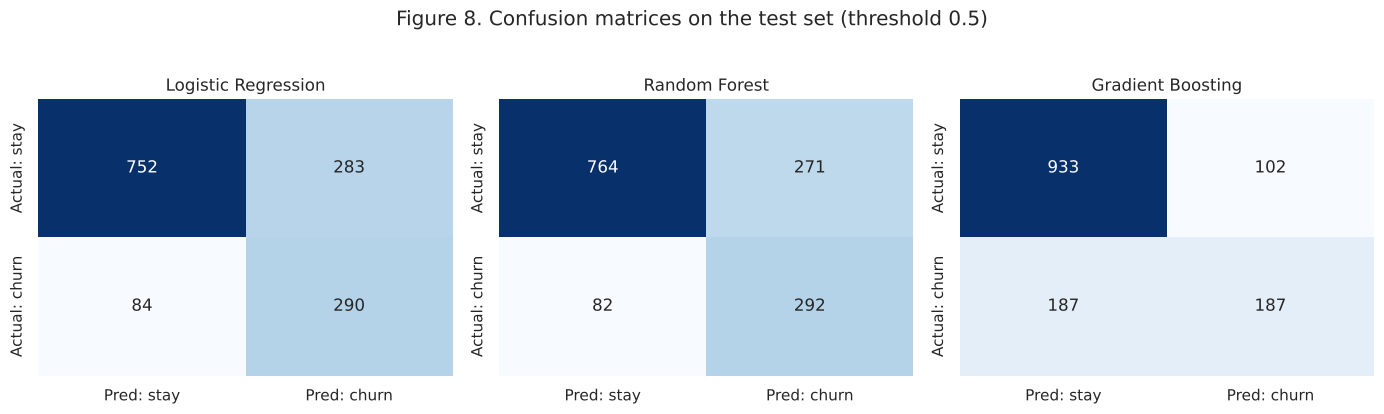

In [18]:
# Confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, p) in zip(axes, probas.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax,
                xticklabels=["Pred: stay", "Pred: churn"], yticklabels=["Actual: stay", "Actual: churn"])
    ax.set_title(name)
fig.suptitle("Figure 8. Confusion matrices on the test set (threshold 0.5)", y=1.03)
save_fig("fig08_confusion_matrices.png")

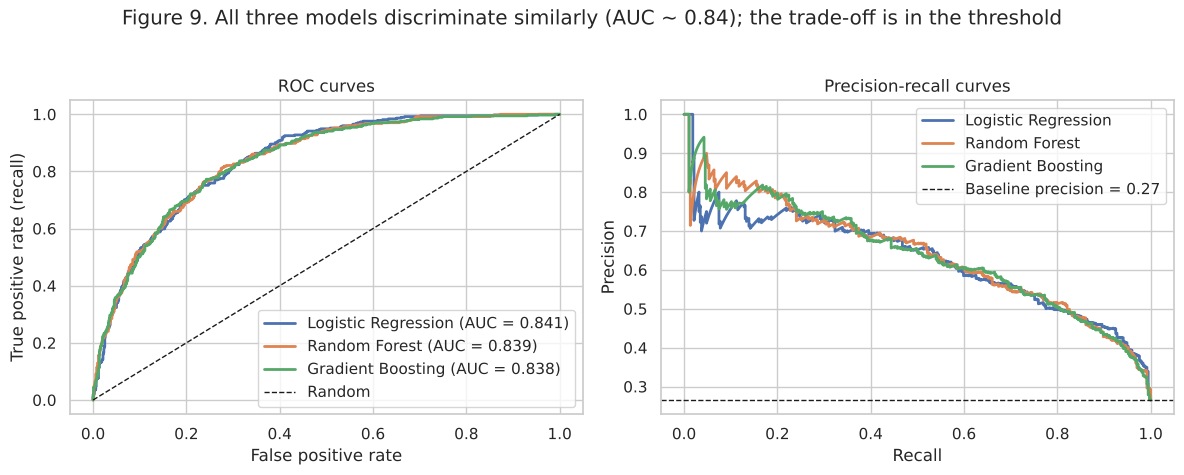

In [19]:
# ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, lw=2, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves"); axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Baseline precision = {y_test.mean():.2f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curves"); axes[1].legend()
fig.suptitle("Figure 9. All three models discriminate similarly (AUC ~ 0.84); the trade-off is in the threshold", y=1.03)
save_fig("fig09_roc_pr_curves.png")

**Reading the results.** The three models are statistically indistinguishable on ROC-AUC (≈ 0.84 both in cross-validation and on the test set) — this is close to the known ceiling for this dataset, because the available features simply do not capture everything that drives a cancellation (competitor offers, service outages, life events).

Where they differ is *how they spend* that discriminative power at the 0.5 threshold:

- The two `class_weight="balanced"` models (Logistic Regression, Random Forest) trade accuracy for recall: they catch ~78 % of churners but only about half of their flags are correct.
- Gradient Boosting, trained without reweighting, is the most accurate (≈ 79 %) and most precise (≈ 64 %) but catches only half the churners at 0.5 — its probabilities are honest, so a 0.5 cut-off is simply too strict for a 26 % base rate.
- Gradient Boosting also has the **lowest Brier score**, i.e. the best-calibrated probabilities. That matters because the business analysis in Section 8 multiplies predicted probabilities by customer value; a model whose "70 %" really means 70 % is worth more than one whose probabilities are inflated by class weighting.

The right comparison is therefore not "which model wins at 0.5" but "which model wins at the threshold the business actually needs", which is Section 6.

## 6. Threshold tuning and calibration

A retention team does not care about a 0.5 cut-off; it cares about the trade-off between **missing a churner** (lost customer) and **contacting someone who was going to stay anyway** (wasted offer). We tune the threshold on **out-of-fold predictions from the training set** so the test set stays untouched, choosing the threshold that maximises F1 for each model.

In [20]:
def best_threshold(pipe, X, y):
    # Out-of-fold probabilities on the training set -> no information from the test set is used
    oof = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
    grid = np.arange(0.15, 0.80, 0.01)
    f1s = [f1_score(y, (oof >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(f1s))]), oof, grid, f1s

tuned_rows, thresholds, curves = [], {}, {}
for name, pipe in pipelines.items():
    t, oof, grid, f1s = best_threshold(pipe, X_train, y_train)
    thresholds[name] = t; curves[name] = (grid, f1s)
    pred = (probas[name] >= t).astype(int)
    tuned_rows.append({"Model": name, "Threshold": t,
                       "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                       "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                       "ROC-AUC": roc_auc_score(y_test, probas[name])})
tuned_table = pd.DataFrame(tuned_rows).set_index("Model")
print("Held-out test set at the CV-tuned threshold:")
tuned_table.round(3)

Held-out test set at the CV-tuned threshold:


,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Logistic Regression,0.58,0.767,0.546,0.727,0.624,0.841
Random Forest,0.55,0.764,0.541,0.730,0.621,0.839
Gradient Boosting,0.31,0.760,0.535,0.743,0.622,0.838


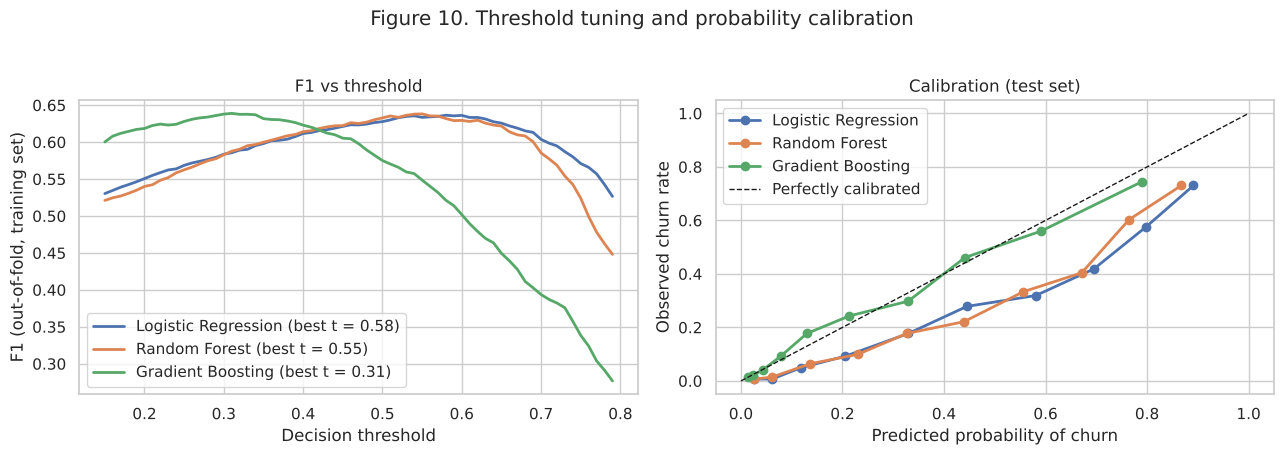

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for name, (grid, f1s) in curves.items():
    axes[0].plot(grid, f1s, lw=2, label=f"{name} (best t = {thresholds[name]:.2f})")
axes[0].set_xlabel("Decision threshold"); axes[0].set_ylabel("F1 (out-of-fold, training set)"); axes[0].set_title("F1 vs threshold")
axes[0].legend()
for name, p in probas.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[1].plot(mean_pred, frac_pos, marker="o", lw=2, label=name)
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Perfectly calibrated")
axes[1].set_xlabel("Predicted probability of churn"); axes[1].set_ylabel("Observed churn rate"); axes[1].set_title("Calibration (test set)")
axes[1].legend()
fig.suptitle("Figure 10. Threshold tuning and probability calibration", y=1.03)
save_fig("fig10_threshold_calibration.png")

**Model selection.** After tuning, the three models are indistinguishable on F1 (≈ 0.62) and within a point of each other on accuracy and precision — once the threshold is set sensibly, the "balanced" models lose their apparent advantage. We select **Gradient Boosting** as the deployment model because:

1. Its probabilities are the **best calibrated** (closest to the diagonal in Figure 10; Brier score 0.139 versus 0.164–0.167 for the other two). The expected-value targeting in Section 8 multiplies predicted probabilities by customer value, so an honest probability is worth more than a slightly higher metric.
2. At its tuned threshold (0.31) it has the **highest recall** of the three (≈ 74 %) at essentially the same precision, i.e. it misses the fewest churners for the same number of wasted offers.
3. Its tuned threshold being 0.31 rather than ~0.55 is itself informative: for a 26 % base rate, a customer with a one-in-three chance of leaving *is* worth attention; the class-weighted models hide this by inflating every probability.

Logistic Regression is retained as the **explanation model**: its coefficients (Section 7) are what we would show the retention team to justify why a customer is flagged.

In [22]:
BEST = "Gradient Boosting"
best_pipe = pipelines[BEST]
BEST_T = thresholds[BEST]
best_proba = probas[BEST]
best_pred = (best_proba >= BEST_T).astype(int)
print(f"Selected model: {BEST} at threshold {BEST_T:.2f}\n")
print(classification_report(y_test, best_pred, target_names=["Stayed", "Churned"], digits=3))

Selected model: Gradient Boosting at threshold 0.31

              precision    recall  f1-score   support

      Stayed      0.892     0.766     0.824      1035
     Churned      0.535     0.743     0.622       374

    accuracy                          0.760      1409
   macro avg      0.713     0.755     0.723      1409
weighted avg      0.797     0.760     0.771      1409



## 7. What drives churn? Feature importance, and correlation vs causation

### 7.1 Logistic regression coefficients (direction and size of each effect)

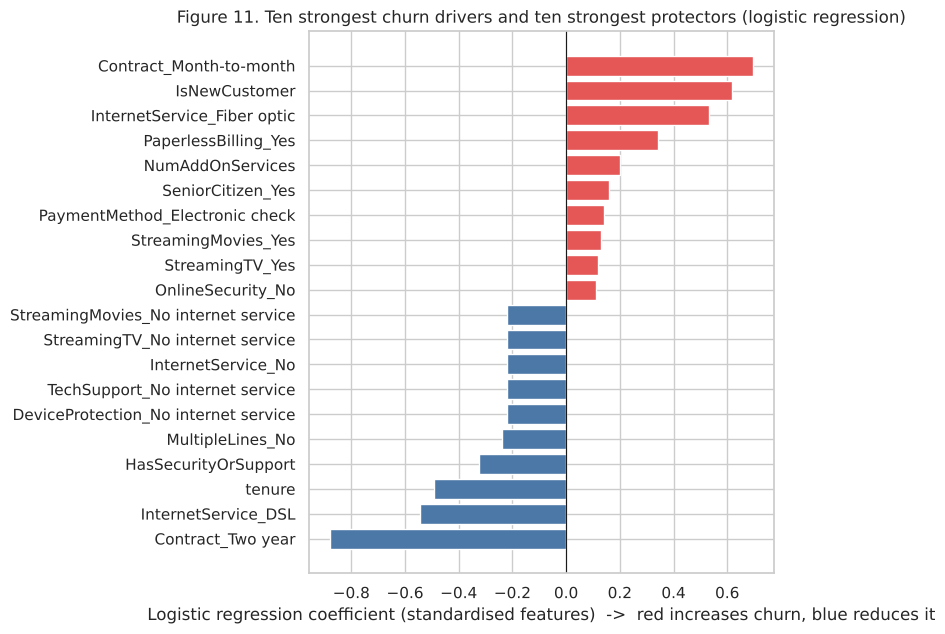

In [23]:
lr_pipe = pipelines["Logistic Regression"]
feat_names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=[f.split("__", 1)[1] for f in feat_names]).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#E45756", "#4C78A8"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Logistic regression coefficient (standardised features)  ->  red increases churn, blue reduces it")
ax.set_title("Figure 11. Ten strongest churn drivers and ten strongest protectors (logistic regression)")
save_fig("fig11_logreg_coefficients.png")

### 7.2 Permutation importance of the selected model

Permutation importance measures how much the test-set ROC-AUC drops when one feature is shuffled. It is computed on the raw feature columns (before one-hot encoding), so multi-category features are assessed as a whole.

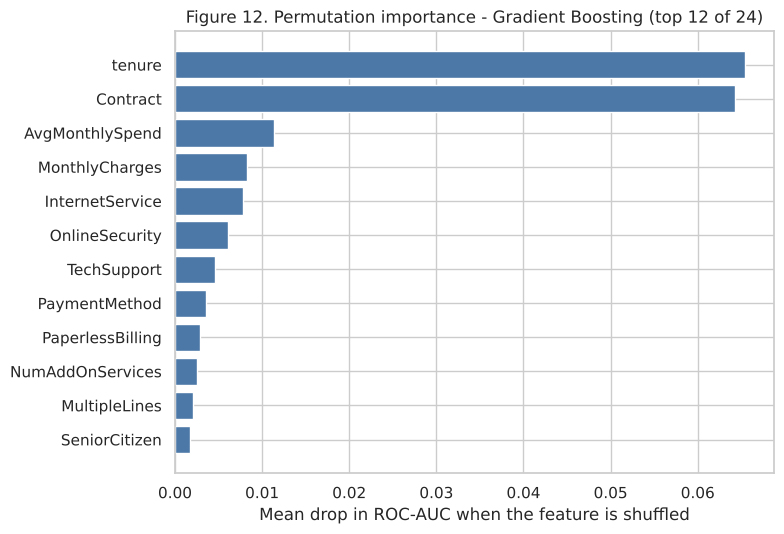

,AUC drop
tenure,0.0655
Contract,0.0642
AvgMonthlySpend,0.0113
MonthlyCharges,0.0083
InternetService,0.0078
OnlineSecurity,0.0061
TechSupport,0.0046
PaymentMethod,0.0035
PaperlessBilling,0.0028
NumAddOnServices,0.0025


In [24]:
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(imp.head(12).index[::-1], imp.head(12).values[::-1], color="#4C78A8")
ax.set_xlabel("Mean drop in ROC-AUC when the feature is shuffled")
ax.set_title(f"Figure 12. Permutation importance - {BEST} (top 12 of {len(FEATURES)})")
save_fig("fig12_permutation_importance.png")
imp.head(12).round(4).to_frame("AUC drop")

### 7.3 Does contract type *cause* churn, or do churn-prone customers simply choose short contracts?

Both models rank contract type and tenure far above everything else, followed by spend level, internet type and the security/support add-ons. But a feature that predicts churn is not necessarily a lever the company can pull. Two checks:

**(a) Does the contract effect survive after controlling for tenure?** Month-to-month customers are also newer customers, so the raw 43 % vs 3 % gap could just be tenure in disguise.

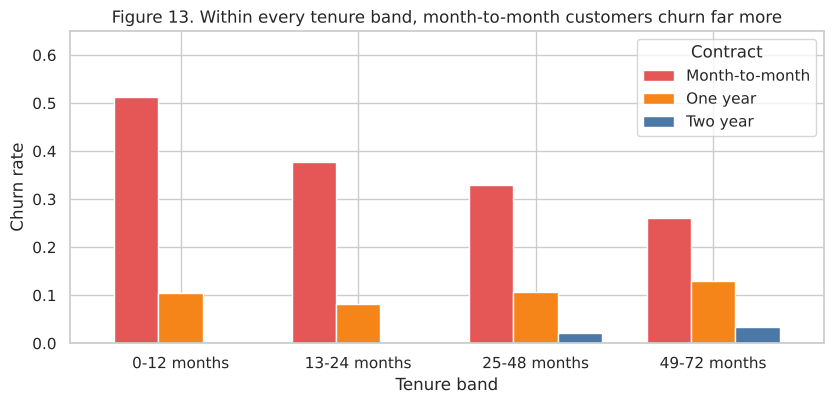

Contract,Month-to-month,One year,Two year
TenureBand,,,
0-12 months,51.4%,10.5%,0.0%
13-24 months,37.7%,8.1%,0.0%
25-48 months,32.9%,10.6%,2.2%
49-72 months,26.0%,12.9%,3.3%


Contract,Month-to-month,One year,Two year
TenureBand,,,
0-12 months,1994,124,68
13-24 months,737,197,90
25-48 months,802,518,274
49-72 months,342,634,1263


In [25]:
ct = df.pivot_table(index="TenureBand", columns="Contract", values="ChurnFlag", aggfunc="mean", observed=True)
ct_n = df.pivot_table(index="TenureBand", columns="Contract", values="ChurnFlag", aggfunc="size", observed=True)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ct.plot(kind="bar", ax=ax, color=["#E45756", "#F58518", "#4C78A8"], width=0.75)
ax.set_ylabel("Churn rate"); ax.set_xlabel("Tenure band"); ax.set_ylim(0, 0.65)
ax.set_title("Figure 13. Within every tenure band, month-to-month customers churn far more")
ax.legend(title="Contract"); plt.xticks(rotation=0)
save_fig("fig13_contract_within_tenure.png")
display(ct.style.format("{:.1%}")); display(ct_n)

The gap is not a tenure artefact: even among customers with 4–6 years of tenure, month-to-month churn (≈ 26 %) is double the one-year rate (≈ 13 %) and eight times the two-year rate (≈ 3 %). **But** this still does not prove causation. Two mechanisms are confounded:

1. **Lock-in (causal):** a two-year contract carries an early-termination fee, which mechanically suppresses churn for its duration.
2. **Self-selection (non-causal):** customers who are unsure about the service, or who expect to move, *choose* month-to-month. Their churn reflects that uncertainty, not the contract itself.

The dataset cannot separate these because it has no record of *why* a customer picked a contract, nor what happens when a locked-in customer's term ends. The honest conclusion: contract type is an excellent **predictor** and plausibly a partial **cause**, so a "migrate to annual contract" offer is worth testing — but its true effect must be measured with an A/B test, not read off this model.

**(b) Fibre optic.** Fibre customers churn at 42 %. Fibre is unlikely to be *worse* than DSL; it is the premium product (median bill ≈ \$90 vs \$55 for DSL), so its customers are the ones for whom a cheaper competitor is most tempting — and they may also be comparing against a higher expectation of quality. The feature is best read as "high-value, price-sensitive segment" rather than "fibre causes churn".

**(c) Electronic check** is the strongest payment-method driver. Nothing about paying by e-check makes people leave; it most likely proxies for customers who deliberately avoid automatic payments — a weaker commitment signal — and possibly for a demographic (no credit card) the dataset does not measure.

In [26]:
df.groupby("InternetService")[["MonthlyCharges", "ChurnFlag"]].agg(["median", "mean"]).round(3)

MonthlyCharges         ChurnFlag       
                        median    mean    median   mean
InternetService                                        
DSL                     56.150  58.102       0.0  0.190
Fiber optic             91.675  91.500       0.0  0.419
No                      20.150  21.079       0.0  0.074

## 8. Business analysis — who should the company actually contact?

A model that flags 500 customers is only useful if the company knows what to do with them. We turn predictions into a decision rule with an **expected-value framework**. The three inputs below are *assumptions*, kept separate from the formula so the retention team can replace them with real figures.

| Assumption | Value used | Rationale |
|---|---|---|
| `RETENTION_HORIZON` | 12 months | Value of a saved customer = one more year of their current monthly bill. Conservative: the median tenure is 29 months. |
| `INTERVENTION_COST` | \$30 per contact | One agent call plus a modest one-off credit. |
| `SAVE_RATE` | 30 % | Share of genuinely at-risk customers who stay after an offer. Industry estimates vary widely (10–50 %); 30 % is a middle value. |

**Expected value of contacting customer *i*:**

$$EV_i = p_i \times \text{SAVE\_RATE} \times \text{RETENTION\_HORIZON} \times \text{MonthlyCharges}_i \;-\; \text{INTERVENTION\_COST}$$

Contact the customer only if $EV_i > 0$. This automatically prioritises customers who are both **likely to leave** and **worth keeping**: a 60 %-risk customer on a \$20 phone-only plan is *not* worth a \$30 offer, while a 35 %-risk customer on a \$105 fibre bundle is.

In [27]:
# ---- Assumptions (edit these; the formula below does not change) ----------
RETENTION_HORIZON = 12     # months of revenue retained if the save succeeds
INTERVENTION_COST = 30.0   # $ per customer contacted
SAVE_RATE = 0.30           # probability an at-risk customer is retained after the offer
# ---------------------------------------------------------------------------

scenario = X_test[["MonthlyCharges", "tenure", "Contract", "InternetService"]].copy()
scenario["actual_churn"] = y_test.values
scenario["p_churn"] = best_proba
scenario["customer_value_12m"] = RETENTION_HORIZON * scenario["MonthlyCharges"]
scenario["expected_value"] = scenario["p_churn"] * SAVE_RATE * scenario["customer_value_12m"] - INTERVENTION_COST
scenario["contact"] = scenario["expected_value"] > 0

def policy_summary(mask, label):
    contacted = scenario[mask]
    saved_rev = (contacted["actual_churn"] * SAVE_RATE * contacted["customer_value_12m"]).sum()
    cost = INTERVENTION_COST * len(contacted)
    return {"Policy": label, "Customers contacted": len(contacted),
            "Churners reached": int(contacted["actual_churn"].sum()),
            "Share of all churners reached": contacted["actual_churn"].sum() / scenario["actual_churn"].sum(),
            "Campaign cost ($)": cost, "Expected revenue saved ($)": saved_rev,
            "Net benefit ($)": saved_rev - cost}

policies = pd.DataFrame([
    policy_summary(scenario["contact"], "A. Expected-value rule (EV > 0)"),
    policy_summary(scenario["p_churn"] >= BEST_T, f"B. Flag everyone above tuned threshold ({BEST_T:.2f})"),
    policy_summary(scenario["p_churn"] >= 0.5, "C. Flag everyone above 0.5"),
    policy_summary(pd.Series(True, index=scenario.index), "D. Contact every customer"),
    policy_summary(pd.Series(np.random.RandomState(RANDOM_STATE).rand(len(scenario)) < scenario["contact"].mean(), index=scenario.index),
                   "E. Random selection (same budget as A)"),
]).set_index("Policy")
print(f"Test set = {len(scenario):,} customers, of whom {int(scenario['actual_churn'].sum())} actually churned\n")
policies.style.format({"Share of all churners reached": "{:.1%}", "Campaign cost ($)": "{:,.0f}",
                       "Expected revenue saved ($)": "{:,.0f}", "Net benefit ($)": "{:,.0f}"})

Test set = 1,409 customers, of whom 374 actually churned



,Customers contacted,Churners reached,Share of all churners reached,Campaign cost ($),Expected revenue saved ($),Net benefit ($)
Policy,,,,,,
A. Expected-value rule (EV > 0),748,323,86.4%,"22,440","89,833","67,393"
B. Flag everyone above tuned threshold (0.31),520,278,74.3%,"15,600","74,701","59,101"
C. Flag everyone above 0.5,289,187,50.0%,"8,670","51,847","43,177"
D. Contact every customer,1409,374,100.0%,"42,270","97,974","55,704"
E. Random selection (same budget as A),740,193,51.6%,"22,200","49,937","27,737"


### 8.1 "The model flags 500 customers — what should we do?"

Suppose the retention budget only allows **500 contacts** out of the 1,409 customers in the test set. Ranking customers by expected value and taking the top 500 tells us how much better the model is than guessing.

Top 500 customers by expected value: 261 of 374 churners (70%) captured by contacting 35% of the base.
Random selection of 500 would capture ~133 churners.
Lift in the top 500: 1.97x the base churn rate.


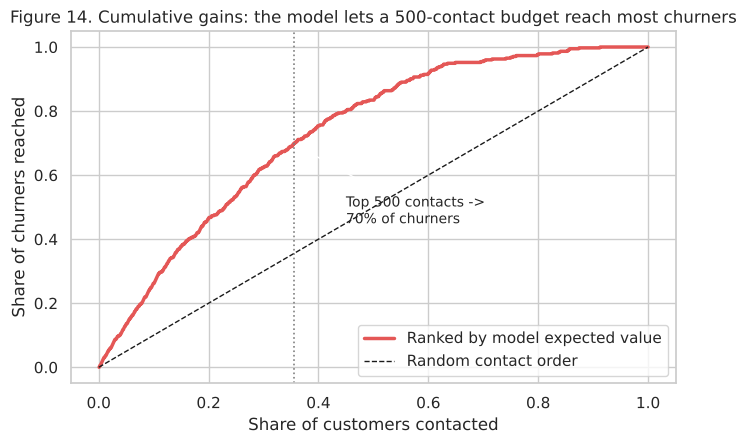

In [28]:
ranked = scenario.sort_values("expected_value", ascending=False).reset_index(drop=True)
ranked["cum_churners"] = ranked["actual_churn"].cumsum()
ranked["cum_share_contacted"] = (ranked.index + 1) / len(ranked)
ranked["cum_share_churners"] = ranked["cum_churners"] / ranked["actual_churn"].sum()
total_churn = int(scenario["actual_churn"].sum())

K = 500
top_k = ranked.head(K)
print(f"Top {K} customers by expected value: {int(top_k['actual_churn'].sum())} of {total_churn} churners "
      f"({top_k['actual_churn'].sum()/total_churn:.0%}) captured by contacting {K/len(ranked):.0%} of the base.")
print(f"Random selection of {K} would capture ~{K/len(ranked)*total_churn:.0f} churners.")
print(f"Lift in the top {K}: {top_k['actual_churn'].mean()/scenario['actual_churn'].mean():.2f}x the base churn rate.")

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.plot(ranked["cum_share_contacted"], ranked["cum_share_churners"], lw=2.5, color="#E45756", label="Ranked by model expected value")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random contact order")
ax.axvline(K/len(ranked), color="grey", ls=":", lw=1.2)
ax.annotate(f"Top {K} contacts ->\n{top_k['actual_churn'].sum()/total_churn:.0%} of churners",
            xy=(K/len(ranked), top_k["actual_churn"].sum()/total_churn), xytext=(0.45, 0.45),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("Share of customers contacted"); ax.set_ylabel("Share of churners reached")
ax.set_title("Figure 14. Cumulative gains: the model lets a 500-contact budget reach most churners")
ax.legend(loc="lower right")
save_fig("fig14_cumulative_gains.png")

### 8.2 Tiered actions, not one offer for everyone

The expected-value ranking combines risk and value. The retention team can translate it into a simple playbook:

| Tier | Who | Suggested action | Why |
|---|---|---|---|
| **1 — Save now** | High risk (p ≥ 0.6) **and** monthly bill ≥ \$70 (fibre bundles, month-to-month, e-check) | Personal call from a retention agent + offer to migrate to a one-year contract with a loyalty discount | Highest expected value; lock-in directly addresses the strongest driver |
| **2 — Nudge** | Moderate risk (0.35 ≤ p < 0.6), any bill | Automated email/SMS: free trial of Online Security or Tech Support; switch to auto-pay incentive | Cheap; the add-ons and auto-pay are the strongest *protective* factors in the data |
| **3 — Monitor** | High risk but low bill (< \$30, phone-only) | No paid offer; include in routine satisfaction survey | A \$30 intervention costs more than a year of their margin |
| **4 — Leave alone** | Low risk (p < 0.35) | Nothing | Contacting happy customers with "don't leave" offers can itself prompt churn |

In [29]:
def tier(row):
    if row.p_churn >= 0.6 and row.MonthlyCharges >= 70: return "1 - Save now"
    if row.p_churn >= 0.35 and row.MonthlyCharges >= 30: return "2 - Nudge"
    if row.p_churn >= 0.35: return "3 - Monitor (low value)"
    return "4 - Leave alone"
scenario["tier"] = scenario.apply(tier, axis=1)
tier_tbl = scenario.groupby("tier").agg(customers=("p_churn", "size"), actual_churn_rate=("actual_churn", "mean"),
                                         avg_monthly_bill=("MonthlyCharges", "mean"), avg_expected_value=("expected_value", "mean")).round(2)
tier_tbl.style.format({"actual_churn_rate": "{:.1%}", "avg_monthly_bill": "${:.0f}", "avg_expected_value": "${:.0f}"})

,customers,actual_churn_rate,avg_monthly_bill,avg_expected_value
tier,,,,
1 - Save now,167,68.0%,$86,$203
2 - Nudge,264,50.0%,$75,$101
3 - Monitor (low value),33,42.0%,$24,$11
4 - Leave alone,945,12.0%,$59,$-4


## 9. Fairness audit

The assignment asks: *if the model flags one group more than another, is that a problem?* We check four demographic attributes on the test set, comparing for each group:

- **Flag rate** — share of the group the model flags (at the tuned threshold).
- **Recall (true-positive rate)** — share of the group's *actual* churners that the model catches. Equal recall across groups is the "equal opportunity" criterion: everyone who is really at risk has the same chance of receiving a retention offer.
- **Precision** — when the model flags someone in the group, how often is it right.

In [30]:
audit = X_test[["gender", "SeniorCitizen", "Partner", "Dependents"]].copy()
audit["y"] = y_test.values; audit["pred"] = best_pred; audit["p"] = best_proba
rows = []
for attr in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    for grp, g in audit.groupby(attr):
        rows.append({"Attribute": attr, "Group": grp, "Customers": len(g),
                     "Actual churn rate": g["y"].mean(), "Flag rate": g["pred"].mean(),
                     "Recall": recall_score(g["y"], g["pred"]), "Precision": precision_score(g["y"], g["pred"])})
fair = pd.DataFrame(rows).set_index(["Attribute", "Group"])
fair.style.format({"Actual churn rate": "{:.1%}", "Flag rate": "{:.1%}", "Recall": "{:.1%}", "Precision": "{:.1%}"})

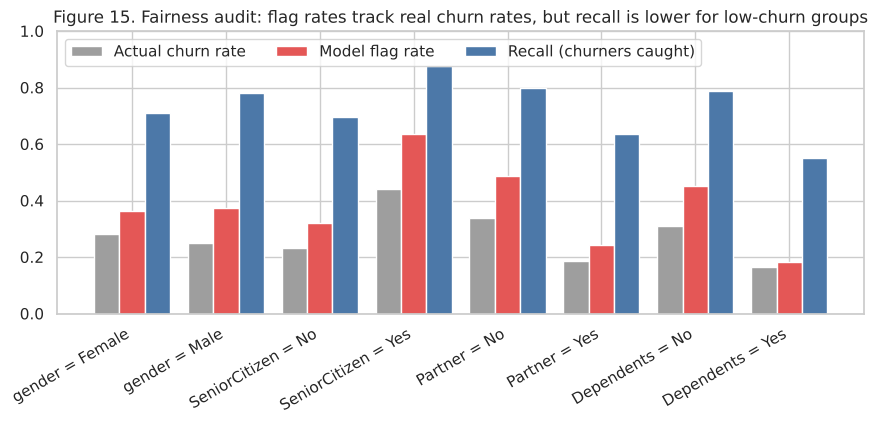

In [31]:
fig, ax = plt.subplots(figsize=(9, 4.4))
plot_df = fair.reset_index()
plot_df["label"] = plot_df["Attribute"] + " = " + plot_df["Group"].astype(str)
xpos = np.arange(len(plot_df)); w = 0.27
ax.bar(xpos - w, plot_df["Actual churn rate"], w, label="Actual churn rate", color="#9E9E9E")
ax.bar(xpos,     plot_df["Flag rate"],         w, label="Model flag rate",   color="#E45756")
ax.bar(xpos + w, plot_df["Recall"],            w, label="Recall (churners caught)", color="#4C78A8")
ax.set_xticks(xpos); ax.set_xticklabels(plot_df["label"], rotation=30, ha="right"); ax.set_ylim(0, 1)
ax.set_title("Figure 15. Fairness audit: flag rates track real churn rates, but recall is lower for low-churn groups")
ax.legend(ncol=3, loc="upper left")
save_fig("fig15_fairness_audit.png")

**Interpretation.**

- **Gender:** flag rates are nearly identical (36 % vs 37 %) and so are churn rates. Recall is 71 % for women vs 78 % for men — a gap small enough to be sampling noise with ~190 churners per group, but one to keep an eye on.
- **Senior citizens, customers without a partner, customers without dependents** are flagged far more often (e.g. seniors 64 % vs 32 %). Each of these groups also *churns* more often in the data (seniors 44 % vs 23 % in the test set), so the model is reflecting a real difference in behaviour, not inventing one.
- **The real finding is in recall.** The model catches 88 % of at-risk seniors but only 70 % of at-risk non-seniors; 79 % of at-risk customers without dependents but only **55 %** of those with dependents; 80 % without a partner vs 64 % with one. This is a known side-effect of using one global threshold: a group with a lower base rate receives lower scores on average, so fewer of its *genuine* churners cross the cut-off.

**Is that a problem?** It depends entirely on what the flag triggers:

- If a flag means the customer *receives a benefit* (a discount, a call, a free add-on), then flagging seniors more often is defensible — the help goes where the risk is. The problem is the mirror image: at-risk customers *with* families are systematically **under-served**, receiving an offer only about half the time. That is an "equal opportunity" failure even though no one intended it.
- If the same score were ever used to *disadvantage* flagged customers — e.g. withholding promotions from people deemed "likely to leave anyway", or offering worse service — then the higher flag rate for seniors would be discriminatory; age is a protected characteristic in most consumer-protection regimes.

We therefore recommend three guard-rails: (1) the score is used only to allocate retention *benefits*, never to restrict service; (2) recall by demographic group is reported every month, with a target that no group's recall falls more than 10 points below the overall figure; (3) if the gap persists, the team should test group-aware thresholds or add features (e.g. household size, service-call history) that explain churn among family customers better — the dataset currently does not.

## 10. Deployment readiness — what we would tell the product manager

**Is the model ready to deploy?** *As a pilot, yes; as a fully automated system, not yet.*

What is solid:
- Discrimination (AUC ≈ 0.84) is stable across cross-validation folds and the hold-out set; probabilities are well calibrated; the drivers it uses are sensible and consistent with the EDA.
- The expected-value rule turns predictions into a decision a budget-constrained team can execute, and it beats random targeting by a wide margin.

What is missing, and would need to be addressed before full roll-out:
1. **No time dimension.** The data is a single snapshot; "churn" means "left last month". We cannot verify that the model predicts *future* churn weeks ahead rather than describing customers who had already decided to leave. A pilot should score customers today and measure churn over the next 60–90 days.
2. **No causal evidence for the interventions.** The model says *who* is at risk, not *what works*. Tier-1 offers should be tested against a hold-out control group before the save rate (assumed 30 %) is trusted.
3. **Precision of roughly 54 %** at the tuned threshold means almost half of contacted customers would have stayed anyway. The cost model handles this, but the offers must be designed so that they do not *remind* a content customer to shop around.
   Add to this the recall gap for family customers found in Section 9.
4. **Missing features** that a real operator has: customer-service call logs, network-quality metrics, competitor pricing, and reason-for-cancellation codes. Adding these is the most likely route past the 0.84 AUC ceiling.
5. **Drift.** Pricing changes or a new competitor would invalidate the learned relationships; the model should be re-trained quarterly and its calibration re-checked.
6. **Governance.** The fairness guard-rails from Section 9 need an owner.

## 11. Export the best model and test it on a new customer

The whole pipeline (preprocessing + Gradient Boosting) is saved as a single `.joblib` file together with the tuned threshold and the feature list, so it can score a raw customer record without any manual preprocessing.

In [32]:
bundle = {
    "pipeline": best_pipe,
    "threshold": BEST_T,
    "features": FEATURES,
    "model_name": BEST,
    "trained_on": "IBM Telco Customer Churn (7,043 customers), 80% stratified training split",
    "created": "2026-10-16",
    "version": "1.0",
}
model_path = os.path.join(MODEL_DIR, "churn_model_gradient_boosting.joblib")
joblib.dump(bundle, model_path)
print(f"Saved model bundle -> {model_path}  ({os.path.getsize(model_path)/1024:.0f} KB)")

Saved model bundle -> ../models/churn_model_gradient_boosting.joblib  (402 KB)


In [33]:
def prepare_customer(record: dict) -> pd.DataFrame:
    # Re-creates the engineered features for a raw customer record (same logic as Section 4)
    r = dict(record)
    r["SeniorCitizen"] = {0: "No", 1: "Yes"}.get(r.get("SeniorCitizen"), r.get("SeniorCitizen"))
    total = float(r.get("TotalCharges") or 0.0)
    r["NumAddOnServices"] = sum(r[a] == "Yes" for a in ADDONS)
    r["HasSecurityOrSupport"] = int(r["OnlineSecurity"] == "Yes" or r["TechSupport"] == "Yes")
    r["AvgMonthlySpend"] = total / max(r["tenure"], 1) if r["tenure"] > 0 else r["MonthlyCharges"]
    r["ChargeRatio"] = r["MonthlyCharges"] / r["AvgMonthlySpend"]
    r["IsNewCustomer"] = int(r["tenure"] <= 12)
    r["AutoPay"] = int("automatic" in r["PaymentMethod"])
    return pd.DataFrame([r])[FEATURES]

# Reload from disk to prove the saved file works on its own
loaded = joblib.load(model_path)

# Test case 1: a textbook high-risk profile (new, fibre, month-to-month, e-check, no add-ons)
new_customer = {"gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 3,
                "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
                "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
                "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month",
                "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check", "MonthlyCharges": 95.4, "TotalCharges": 286.2}
# Test case 2: a textbook loyal profile (long tenure, two-year, auto-pay, security + support)
loyal_customer = {**new_customer, "tenure": 60, "Contract": "Two year", "PaymentMethod": "Credit card (automatic)",
                  "OnlineSecurity": "Yes", "TechSupport": "Yes", "Partner": "Yes", "MonthlyCharges": 85.0, "TotalCharges": 5100.0}

for label, rec in [("High-risk new fibre customer", new_customer), ("Loyal two-year customer", loyal_customer)]:
    p = loaded["pipeline"].predict_proba(prepare_customer(rec))[:, 1][0]
    flag = "FLAG - contact" if p >= loaded["threshold"] else "no action"
    ev = p * SAVE_RATE * RETENTION_HORIZON * rec["MonthlyCharges"] - INTERVENTION_COST
    print(f"{label:30s} | P(churn) = {p:.1%} | threshold {loaded['threshold']:.2f} -> {flag:15s} | expected value of an offer: ${ev:,.0f}")

High-risk new fibre customer   | P(churn) = 85.9% | threshold 0.31 -> FLAG - contact  | expected value of an offer: $265
Loyal two-year customer        | P(churn) = 3.4% | threshold 0.31 -> no action       | expected value of an offer: $-20


In [34]:
# Save headline numbers for the written report
summary = {
    "n_customers": int(len(df)), "churn_rate": float(churn_rate), "n_test": int(len(X_test)), "test_churners": total_churn,
    "cv": cv_table.to_dict(), "test_at_0.5": test_table.round(3).to_dict(), "test_tuned": tuned_table.round(3).to_dict(),
    "thresholds": thresholds, "best_model": BEST, "best_threshold": BEST_T,
    "permutation_importance_top": imp.head(10).round(4).to_dict(),
    "policies": policies.round(2).to_dict(), "top500_churners": int(top_k["actual_churn"].sum()),
    "fairness": fair.round(3).reset_index().to_dict(orient="records"),
    "contract_within_tenure": ct.round(3).to_dict(), "tiers": tier_tbl.to_dict(),
}
with open(os.path.join(FIG_DIR, "results_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)
print("Saved results_summary.json")

Saved results_summary.json


## 12. Conclusion

**Main insight.** Churn in this telecom is overwhelmingly a *first-year, month-to-month, fibre-optic, electronic-check* phenomenon. The strongest *protective* factors — longer contracts, automatic payment and security/support add-ons — are all things the company can offer, which makes retention a product-design problem as much as a prediction problem.

**Model.** Three classifiers reached the same discriminative ceiling (ROC-AUC ≈ 0.84). Gradient Boosting was selected for its calibration; at the tuned threshold of 0.31 it catches about three in four churners (recall 74 %) with precision of 54 % and accuracy of 76 %.

**Business value.** An expected-value rule that weighs churn risk against customer value reaches 86 % of churners by contacting about half the base and produces the highest net benefit of every policy tested (≈ \$67k on the 1,409-customer test set, versus ≈ \$56k for contacting everyone and ≈ \$28k for a random campaign of the same size). With a 500-contact budget the model captures about 70 % of churners, double what random targeting would.

**Caveats.** Contract type and fibre predict churn but are partly self-selected; the interventions must be A/B-tested; the model should be used only to allocate benefits; recall must be monitored by demographic group because at-risk customers with families are currently caught only about half the time; and a 60–90-day forward-looking pilot is needed before full deployment.